# PrediCare TPA — Exploration & Features (Version 1)

**Objectif** : explorer les données et construire ~23 variables métier correctes pour la détection de fraude.

**Schéma réel utilisé**
- Ordonnances : `date_prescription`, `validite_jours` (pas `date_fin_validite`)
- Lignes : colonne `code` (pas `code_acte`)
- Grille : `prestataire_id` + `code` → `tarif_pratique`
- Prestataires : `jours_ouverture`, `date_fin_convention`

**Contraintes**
- Pas de PII / `identites_pii`
- Pas de fuites : `statut`, `motif_rejet`, `montant_pris_en_charge`, `date_traitement`, `reste_a_charge`, `montant_eligible`
- Cible : `est_fraude` ; `labels_prestataires` = descriptif uniquement
- NA métier conservés

**Livrables** : `processed/features_v1.csv`, `schema_v1.json`, graphiques dans `reports/`

## 0. Configuration

In [ ]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

# --- Adapter selon l'environnement ---
DATA = Path(".//data")
LABELS = Path("./labels")
# Colab exemple : DATA = Path("/content/data") ; LABELS = Path("/content/labels")

OUT = Path("./processed")
REPORTS = Path("./reports")
OUT.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

FUITE = [
    "statut", "motif_rejet", "montant_pris_en_charge",
    "date_traitement", "reste_a_charge", "montant_eligible",
]

print("DATA:", DATA.exists(), "| LABELS:", LABELS.exists())

DATA: True | LABELS: True


:## 1. Chargement

In [ ]:
tables = {}
for nom in [
    "factures", "lignes_facture", "ordonnances", "ordonnance_lignes",
    "assures", "contrats", "prestataires", "grille_tarifaire", "referentiel_actes",
]:
    tables[nom] = pd.read_csv(DATA / f"{nom}.csv", low_memory=False)
    print(f"{nom:25s} {tables[nom].shape}")

labels = pd.read_csv(LABELS / "labels_fraude.csv", low_memory=False)
print(f"{'labels_fraude':25s} {labels.shape}")

# Dates — uniquement si la colonne existe
for t, cols in {
    "factures": ["date_soin", "date_facture", "date_reception"],
    "ordonnances": ["date_prescription"],
    "assures": ["date_adhesion", "date_radiation"],
    "prestataires": ["date_conventionnement", "date_fin_convention", "date_debut_convention"],
}.items():
    for c in cols:
        if c in tables[t].columns:
            tables[t][c] = pd.to_datetime(tables[t][c], errors="coerce")

# Heure de soin
f0 = tables["factures"]
if "heure_soin" in f0.columns:
    tables["factures"]["heure_soin_dt"] = pd.to_datetime(
        f0["heure_soin"].astype(str), format="%H:%M", errors="coerce"
    )
    tables["factures"]["heure_soin_h"] = tables["factures"]["heure_soin_dt"].dt.hour

assert tables["factures"]["facture_id"].is_unique
print("\nOK — facture_id unique")
print("Colonnes ordonnances :", list(tables["ordonnances"].columns))
print("Colonnes lignes      :", list(tables["lignes_facture"].columns))

factures                  (84593, 24)
lignes_facture            (123270, 9)
ordonnances               (47804, 8)
ordonnance_lignes         (82175, 6)
assures                   (4459, 9)
contrats                  (1500, 12)
prestataires              (251, 20)
grille_tarifaire          (3242, 3)
referentiel_actes         (58, 12)
labels_fraude             (84593, 6)

OK — facture_id unique
Colonnes ordonnances : ['ordonnance_id', 'assure_id', 'prescripteur_id', 'date_prescription', 'validite_jours', 'type_ordonnance', 'diagnostic', 'renseignement_clinique']
Colonnes lignes      : ['ligne_id', 'facture_id', 'num_ligne', 'code', 'type_ligne', 'libelle', 'quantite', 'prix_unitaire', 'montant']


## 2. Audit qualité

In [ ]:
def audit(df, name):
    return {
        "table": name,
        "lignes": len(df),
        "colonnes": df.shape[1],
        "pct_na_max": float(df.isna().mean().max() * 100),
        "doublons": int(df.duplicated().sum()),
    }

rows = [audit(tables[n], n) for n in tables]
rows.append(audit(labels, "labels_fraude"))
audit_df = pd.DataFrame(rows)
display(audit_df)

presentes = [c for c in FUITE if c in tables["factures"].columns]
print("Colonnes de fuite (audit only, jamais en X) :", presentes or "aucune")

,table,lignes,colonnes,pct_na_max,doublons
0,factures,84593,26,99.612261,0
1,lignes_facture,123270,9,0.000000,0
2,ordonnances,47804,8,0.399548,0
3,ordonnance_lignes,82175,6,8.266504,0
4,assures,4459,9,92.621664,0
5,contrats,1500,12,92.733333,0
6,prestataires,251,20,96.414343,0
7,grille_tarifaire,3242,3,0.000000,0
8,referentiel_actes,58,12,87.931034,0
9,labels_fraude,84593,6,100.000000,0


Colonnes de fuite (audit only, jamais en X) : ['statut', 'motif_rejet', 'montant_pris_en_charge', 'date_traitement', 'reste_a_charge', 'montant_eligible']


## 3. Visualisations

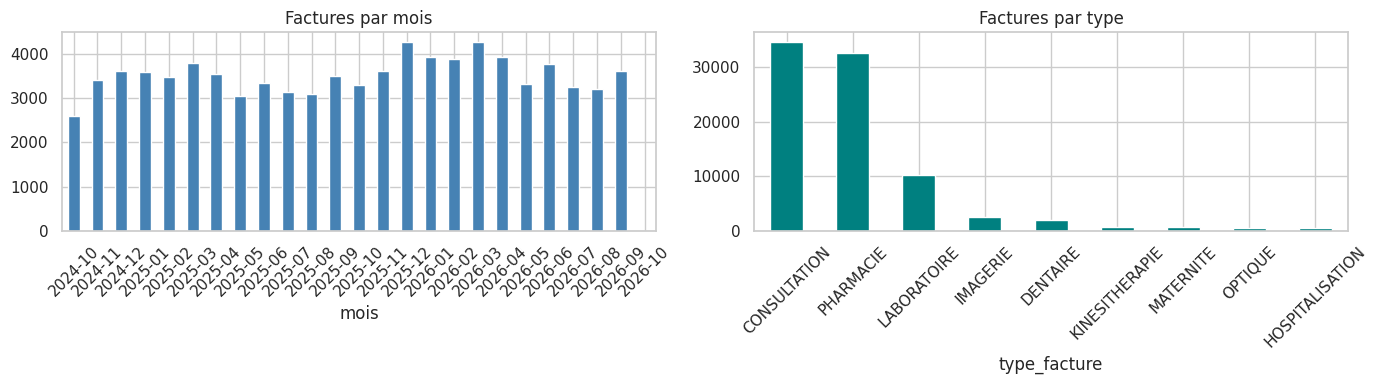

In [ ]:
factures = tables["factures"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Volume mensuel
tmp = factures.copy()
tmp["mois"] = tmp["date_soin"].dt.to_period("M").astype(str)
tmp.groupby("mois").size().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Factures par mois")
axes[0].tick_params(axis="x", rotation=45)

# Par type
if "type_facture" in factures.columns:
    factures["type_facture"].value_counts().plot(kind="bar", ax=axes[1], color="teal")
    axes[1].set_title("Factures par type")
    axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(REPORTS / "01_volume_type.png", dpi=120)
plt.show()

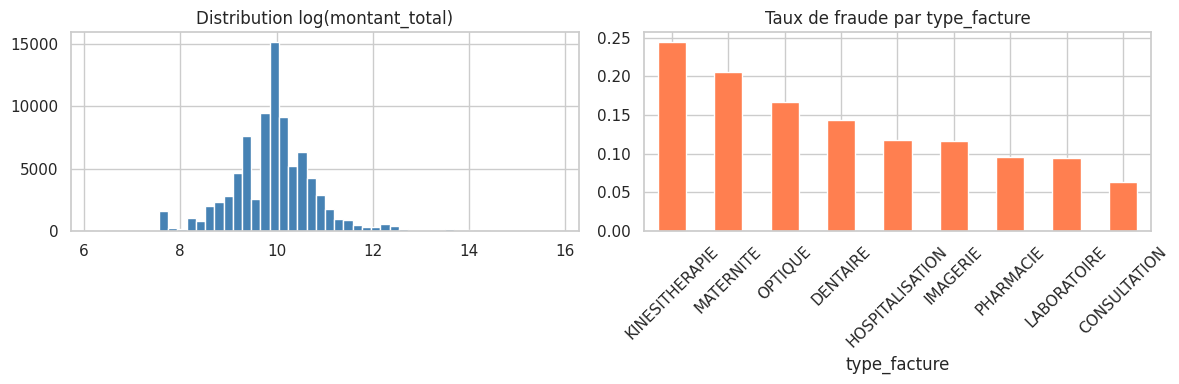

Taux fraude global : 8.69%
type_fraude
SURFACTURATION           1272
DOUBLON                   909
UPCODING                  742
LIGNES_NON_PRESCRITES     733
QUANTITE_EXCESSIVE        568
ORDONNANCE_EXPIREE        502
ACTE_FICTIF               496
SURCONSOMMATION           469
INCOHERENCE_PROFIL        379
SUBSTITUTION_PRODUIT      368
FRACTIONNEMENT            340
SOINS_JOUR_FERME          227
HORS_COUVERTURE           195
PRESTATAIRE_RADIE         147
Name: count, dtype: int64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

mt = factures["montant_total"].dropna()
axes[0].hist(np.log1p(mt), bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution log(montant_total)")

lab = labels.merge(factures[["facture_id", "type_facture"]], on="facture_id", how="left")
taux = lab.groupby("type_facture")["est_fraude"].mean().sort_values(ascending=False)
taux.plot(kind="bar", ax=axes[1], color="coral")
axes[1].set_title("Taux de fraude par type_facture")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(REPORTS / "01_montants_taux.png", dpi=120)
plt.show()

print(f"Taux fraude global : {labels['est_fraude'].mean():.2%}")
print(labels["type_fraude"].value_counts().head(15))

## 4. Construction des features (schéma correct)

Socle + signaux DOUBLON / UPCODING / JOUR_FERME.

In [ ]:
f = tables["factures"].drop(columns=[c for c in FUITE if c in tables["factures"].columns]).copy()
assures = tables["assures"][["assure_id", "date_adhesion", "date_radiation"]]

prest_cols = ["prestataire_id", "type_prestataire", "date_fin_convention", "jours_ouverture"]
for c in ["specialite", "niveau_tarif", "heure_ouverture", "heure_fermeture", "date_conventionnement"]:
    if c in tables["prestataires"].columns:
        prest_cols.append(c)
prest = tables["prestataires"][[c for c in prest_cols if c in tables["prestataires"].columns]].copy()
if "specialite" in prest.columns:
    prest = prest.rename(columns={"specialite": "presta_specialite"})

fact = f.merge(assures, on="assure_id", how="left").merge(prest, on="prestataire_id", how="left")
print("fact enrichi :", fact.shape)

fact enrichi : (84593, 30)


In [ ]:
# --- Lignes + ratios tarifs ---
lignes = tables["lignes_facture"].copy()
lignes["montant_ligne_calcule"] = lignes["quantite"] * lignes["prix_unitaire"]

agg = lignes.groupby("facture_id").agg(
    quantite_totale=("quantite", "sum"),
    prix_unitaire_max=("prix_unitaire", "max"),
).reset_index()

grille = tables["grille_tarifaire"]
codes = (
    lignes[["facture_id", "code", "prix_unitaire"]]
    .merge(f[["facture_id", "prestataire_id"]], on="facture_id", how="left")
    .merge(grille, on=["prestataire_id", "code"], how="left")
)
codes["ratio_tarif"] = codes["prix_unitaire"] / codes["tarif_pratique"].replace(0, np.nan)
prix_agg = codes.groupby("facture_id").agg(ratio_tarif_max=("ratio_tarif", "max")).reset_index()
agg = agg.merge(prix_agg, on="facture_id", how="left")
fact = fact.merge(agg, on="facture_id", how="left")

print("Lignes + ratio_tarif_max OK")

Lignes + ratio_tarif_max OK


In [ ]:
# --- Ordonnance (validite_jours) ---
fact["a_ordonnance"] = fact["ordonnance_id"].notna().astype("int8")

ordo = tables["ordonnances"][["ordonnance_id", "assure_id", "date_prescription", "validite_jours"]].rename(
    columns={"assure_id": "ord_assure_id"}
)
fact = fact.merge(ordo, on="ordonnance_id", how="left")
fact["delai_ord_jours"] = (fact["date_soin"] - fact["date_prescription"]).dt.days
fact["ord_perimee"] = (fact["delai_ord_jours"] > fact["validite_jours"]).fillna(False).astype("int8")
fact["ord_apres_soin"] = (fact["delai_ord_jours"] < 0).fillna(False).astype("int8")
fact["ord_autre_assure"] = (
    fact["ord_assure_id"].notna() & (fact["assure_id"] != fact["ord_assure_id"])
).astype("int8")

# Lignes non prescrites / qté excessive
lo = lignes[["facture_id", "code", "quantite"]].merge(
    f[["facture_id", "ordonnance_id"]], on="facture_id", how="left"
)
lo = lo.dropna(subset=["ordonnance_id"]).merge(
    tables["ordonnance_lignes"][["ordonnance_id", "code", "quantite"]].rename(
        columns={"quantite": "qte_prescrite"}
    ),
    on=["ordonnance_id", "code"], how="left",
)
lo["non_prescrite"] = lo["qte_prescrite"].isna()
lo["qte_excedentaire"] = lo["qte_prescrite"].notna() & (lo["quantite"] > lo["qte_prescrite"])
lo_agg = lo.groupby("facture_id").agg(
    nb_lignes_non_prescrites=("non_prescrite", "sum"),
    nb_lignes_qte_excedentaire=("qte_excedentaire", "sum"),
).reset_index()
fact = fact.merge(lo_agg, on="facture_id", how="left")
for c in ["nb_lignes_non_prescrites", "nb_lignes_qte_excedentaire"]:
    fact[c] = fact[c].fillna(0).astype("int32")

print("Ordonnance OK — ord_perimee=1 :", int(fact["ord_perimee"].sum()))
print("  nb_lignes_non_prescrites > 0 :", int((fact["nb_lignes_non_prescrites"] > 0).sum()))

Ordonnance OK — ord_perimee=1 : 594
  nb_lignes_non_prescrites > 0 : 1276


In [ ]:
# --- Couverture / convention ---
fact["soin_avant_adhesion"] = (fact["date_soin"] < fact["date_adhesion"]).fillna(False).astype("int8")
fact["soin_apres_radiation"] = (
    fact["date_radiation"].notna() & (fact["date_soin"] > fact["date_radiation"])
).astype("int8")
fact["presta_apres_fin_convention"] = (
    fact["date_fin_convention"].notna() & (fact["date_soin"] > fact["date_fin_convention"])
).astype("int8")

fact["jour_semaine_soin"] = fact["date_soin"].dt.dayofweek  # 0=lun ... 6=dim

# Répétition même clé
cle = ["assure_id", "prestataire_id", "montant_total", "date_soin"]
fact["nb_factures_meme_cle"] = fact.groupby(cle)["facture_id"].transform("size")
fact["repetition_potentielle"] = (fact["nb_factures_meme_cle"] > 1).astype("int8")
fact["nb_factures_meme_jour_prestataire"] = fact.groupby(
    ["assure_id", "prestataire_id", "date_soin"]
)["facture_id"].transform("size")

print("Couverture / répétition OK")
print("  ord_perimee / presta_radie / soin_avant_adhesion :",
      int(fact["ord_perimee"].sum()),
      int(fact["presta_apres_fin_convention"].sum()),
      int(fact["soin_avant_adhesion"].sum()))

Couverture / répétition OK
  ord_perimee / presta_radie / soin_avant_adhesion : 594 157 134


In [ ]:
# --- DOUBLON / fenêtre 7 j ---
ft = fact[["facture_id", "assure_id", "prestataire_id", "date_soin", "montant_total"]].copy()
ft = ft.dropna(subset=["date_soin", "assure_id"]).sort_values(["assure_id", "date_soin", "facture_id"])

def count_rolling_7d(group):
    g = group.set_index("date_soin").sort_index()
    cnt = g["facture_id"].rolling("7D").count()
    return cnt.reindex(group.set_index("date_soin").index).values

ft["nb_factures_assure_7j"] = (
    ft.groupby("assure_id", group_keys=False)
      .apply(lambda g: pd.Series(count_rolling_7d(g), index=g.index))
)

ft["date_soin_prev"] = ft.groupby("assure_id")["date_soin"].shift(1)
ft["delai_heures_facture_precedente"] = (
    (ft["date_soin"] - ft["date_soin_prev"]).dt.total_seconds() / 3600.0
)
ft["montant_prev"] = ft.groupby("assure_id")["montant_total"].shift(1)
ft["montant_identique_48h"] = (
    (ft["montant_prev"] == ft["montant_total"]) &
    (ft["delai_heures_facture_precedente"].notna()) &
    (ft["delai_heures_facture_precedente"] <= 48)
).astype("int8")

print("Fenêtre temporelle OK")
print(ft[["nb_factures_assure_7j", "delai_heures_facture_precedente", "montant_identique_48h"]].describe())

Fenêtre temporelle OK
       nb_factures_assure_7j  delai_heures_facture_precedente  \
count           84593.000000                     80218.000000   
mean                1.926956                       590.809943   
std                 1.018864                      1281.479272   
min                 1.000000                         0.000000   
25%                 1.000000                        24.000000   
50%                 2.000000                        72.000000   
75%                 2.000000                       576.000000   
max                11.000000                     16224.000000   

       montant_identique_48h  
count           84593.000000  
mean                0.011242  
std                 0.105432  
min                 0.000000  
25%                 0.000000  
50%                 0.000000  
75%                 0.000000  
max                 1.000000  


In [ ]:
# --- Même code sur 7 j ---
codes_f = (
    lignes[["facture_id", "code"]]
    .merge(fact[["facture_id", "assure_id", "date_soin"]], on="facture_id", how="left")
    .dropna(subset=["assure_id", "date_soin"])
    .sort_values(["assure_id", "code", "date_soin"])
)
codes_f["nb_code_assure_7j"] = (
    codes_f.groupby(["assure_id", "code"], group_keys=False)
           .apply(lambda g: pd.Series(
               g.set_index("date_soin")["facture_id"].rolling("7D").count().values,
               index=g.index,
           ))
)
code_agg = codes_f.groupby("facture_id")["nb_code_assure_7j"].max().rename("nb_factures_meme_code_7j")
ft = ft.merge(code_agg, on="facture_id", how="left")
ft["nb_factures_meme_code_7j"] = ft["nb_factures_meme_code_7j"].fillna(1)
print("nb_factures_meme_code_7j OK")

nb_factures_meme_code_7j OK


In [ ]:
# --- UPCODING : majoration horaire incohérente ---
ref = tables["referentiel_actes"].copy()
codes_maj = ref.loc[
    ref["libelle"].str.contains("nuit|dimanche|férié|ferie", case=False, na=False),
    "code_acte",
].tolist()
print("Codes majoration :", codes_maj)

lignes["est_majoration"] = lignes["code"].isin(codes_maj).astype("int8")
maj_par_facture = lignes.groupby("facture_id")["est_majoration"].max().rename("a_majoration_nuit_dimanche")
fact = fact.merge(maj_par_facture, on="facture_id", how="left")
fact["a_majoration_nuit_dimanche"] = fact["a_majoration_nuit_dimanche"].fillna(0).astype("int8")

if "heure_soin_h" not in fact.columns and "heure_soin_h" in tables["factures"].columns:
    fact = fact.merge(tables["factures"][["facture_id", "heure_soin_h"]], on="facture_id", how="left")

fact["majoration_horaire_incoherente"] = (
    (fact["a_majoration_nuit_dimanche"] == 1) &
    (fact["jour_semaine_soin"] < 5) &
    (fact["heure_soin_h"].between(8, 17, inclusive="both"))
).astype("int8")
print("majoration_horaire_incoherente :", int(fact["majoration_horaire_incoherente"].sum()))

# ratio référentiel national
ref_tarifs = ref.set_index("code_acte")[["tarif_max", "tarif_reference"]].to_dict("index")

def ratio_ref_max(row_code, row_prix):
    info = ref_tarifs.get(row_code)
    if not info:
        return np.nan
    tmax = info.get("tarif_max") or info.get("tarif_reference")
    if tmax is None or tmax == 0:
        return np.nan
    return row_prix / tmax

lignes["ratio_ref"] = [ratio_ref_max(c, p) for c, p in zip(lignes["code"], lignes["prix_unitaire"])]
ref_agg = lignes.groupby("facture_id")["ratio_ref"].max().rename("ratio_tarif_referentiel_max")
fact = fact.merge(ref_agg, on="facture_id", how="left")

# Upcoding spécialité / urgence
codes_up = ref.loc[
    ref["code_acte"].str.contains("URG|ENDOC|CARDIO|SPE", case=False, na=False), "code_acte"
].tolist()
lignes["code_spe_urg"] = lignes["code"].isin(codes_up).astype("int8")
spe_agg = lignes.groupby("facture_id")["code_spe_urg"].max().rename("a_code_specialiste_urgence")
fact = fact.merge(spe_agg, on="facture_id", how="left")
fact["a_code_specialiste_urgence"] = fact["a_code_specialiste_urgence"].fillna(0).astype("int8")

fact["upcoding_specialite_suspect"] = (
    (fact["a_code_specialiste_urgence"] == 1) &
    (fact["type_prestataire"].astype(str).str.contains("GENERAL|PHARMA|CABINET", case=False, na=False))
).astype("int8")
print("upcoding_specialite_suspect :", int(fact["upcoding_specialite_suspect"].sum()))

Codes majoration : ['CONS-GEN-MAJ']
majoration_horaire_incoherente : 197
upcoding_specialite_suspect : 815


In [ ]:
# --- SOINS_JOUR_FERME ---
def jour_ouvre_presta(jours_str, dayofweek):
    if pd.isna(jours_str) or pd.isna(dayofweek):
        return np.nan
    s = str(int(jours_str)) if str(jours_str).replace(".", "").isdigit() else str(jours_str)
    code = str(int(dayofweek) + 1)  # pandas 0=lun → '1'
    return 1.0 if code in s else 0.0

fact["ouvert_ce_jour"] = [
    jour_ouvre_presta(j, d) for j, d in zip(fact["jours_ouverture"], fact["jour_semaine_soin"])
]
fact["soin_jour_ferme"] = (fact["ouvert_ce_jour"] == 0.0).astype("int8")
fact.loc[fact["ouvert_ce_jour"].isna(), "soin_jour_ferme"] = 0
print("soin_jour_ferme :", int(fact["soin_jour_ferme"].sum()))

soin_jour_ferme : 474


## 5. Assemblage + contrôle des signaux purs

In [ ]:
cols_ft = [
    "facture_id", "nb_factures_assure_7j", "delai_heures_facture_precedente",
    "montant_identique_48h", "nb_factures_meme_code_7j",
]
fact = fact.merge(ft[cols_ft], on="facture_id", how="left")

FEATURES = [
    "ord_perimee", "nb_lignes_non_prescrites", "nb_lignes_qte_excedentaire",
    "presta_apres_fin_convention", "ord_apres_soin", "ord_autre_assure",
    "soin_avant_adhesion", "soin_apres_radiation",
    "ratio_tarif_max", "prix_unitaire_max", "montant_total",
    "repetition_potentielle", "nb_factures_meme_jour_prestataire",
    "type_facture", "a_ordonnance",
    "nb_factures_assure_7j", "nb_factures_meme_code_7j",
    "delai_heures_facture_precedente", "montant_identique_48h",
    "majoration_horaire_incoherente", "ratio_tarif_referentiel_max",
    "upcoding_specialite_suspect", "soin_jour_ferme",
]
FEATURES = [c for c in FEATURES if c in fact.columns]
print(f"Nb variables : {len(FEATURES)}")
print(FEATURES)

export = fact[["facture_id"] + FEATURES].copy()
export = export.merge(labels[["facture_id", "est_fraude", "type_fraude"]], on="facture_id", how="inner")
export = export.replace([np.inf, -np.inf], np.nan)
print("Export shape :", export.shape)
print(f"Taux fraude : {export['est_fraude'].mean():.2%}")

Nb variables : 23
['ord_perimee', 'nb_lignes_non_prescrites', 'nb_lignes_qte_excedentaire', 'presta_apres_fin_convention', 'ord_apres_soin', 'ord_autre_assure', 'soin_avant_adhesion', 'soin_apres_radiation', 'ratio_tarif_max', 'prix_unitaire_max', 'montant_total', 'repetition_potentielle', 'nb_factures_meme_jour_prestataire', 'type_facture', 'a_ordonnance', 'nb_factures_assure_7j', 'nb_factures_meme_code_7j', 'delai_heures_facture_precedente', 'montant_identique_48h', 'majoration_horaire_incoherente', 'ratio_tarif_referentiel_max', 'upcoding_specialite_suspect', 'soin_jour_ferme']
Export shape : (84593, 26)
Taux fraude : 8.69%


In [ ]:
# Contrôle : taux de fraude quand signal = 1 (doit être très élevé pour les règles pures)
y = export["est_fraude"].astype(int)
print("Taux fraude global :", f"{y.mean()*100:.2f}%\n")
print("Signaux purs / binaires :")
for col in [
    "ord_perimee", "nb_lignes_non_prescrites", "nb_lignes_qte_excedentaire",
    "presta_apres_fin_convention", "ord_apres_soin", "ord_autre_assure",
    "soin_avant_adhesion", "soin_apres_radiation", "repetition_potentielle",
    "montant_identique_48h", "majoration_horaire_incoherente",
    "upcoding_specialite_suspect", "soin_jour_ferme",
]:
    if col not in export.columns:
        continue
    mask = export[col].fillna(0) > 0
    if mask.sum() == 0:
        print(f"  {col:40s} n=0  (signal absent — vérifier)")
        continue
    print(f"  {col:40s} n={mask.sum():6d}  taux_fraude={y[mask].mean()*100:.1f}%")

Taux fraude global : 8.69%

Signaux purs / binaires :
  ord_perimee                              n=   594  taux_fraude=100.0%
  nb_lignes_non_prescrites                 n=  1276  taux_fraude=100.0%
  nb_lignes_qte_excedentaire               n=   564  taux_fraude=100.0%
  presta_apres_fin_convention              n=   157  taux_fraude=100.0%
  ord_apres_soin                           n=   138  taux_fraude=100.0%
  ord_autre_assure                         n=   175  taux_fraude=100.0%
  soin_avant_adhesion                      n=   134  taux_fraude=100.0%
  soin_apres_radiation                     n=    52  taux_fraude=100.0%
  repetition_potentielle                   n=  1350  taux_fraude=45.6%
  montant_identique_48h                    n=   951  taux_fraude=59.7%
  majoration_horaire_incoherente           n=   197  taux_fraude=100.0%
  upcoding_specialite_suspect              n=   815  taux_fraude=35.7%
  soin_jour_ferme                          n=   474  taux_fraude=98.5%


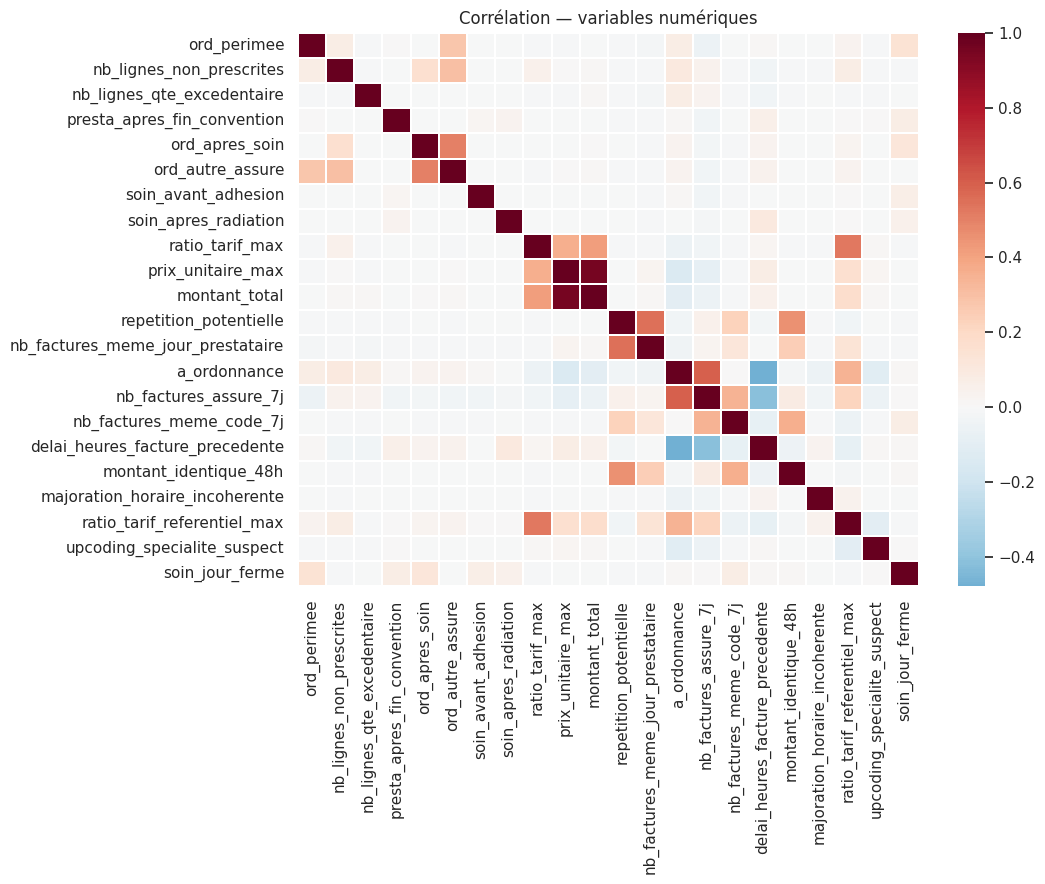

In [ ]:
# Corrélation numériques
num_feats = [c for c in FEATURES if c != "type_facture" and pd.api.types.is_numeric_dtype(export[c])]
corr = export[num_feats].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, ax=ax, linewidths=0.3)
ax.set_title("Corrélation — variables numériques")
plt.tight_layout()
plt.savefig(REPORTS / "01_correlation.png", dpi=120)
plt.show()

Top 15 prestataires (volume ≥ 20) — audit uniquement


,n_factures,n_fraudes,taux_fraude
prestataire_id,,,
PRE-00114,39,33,0.846154
PRE-00132,25,21,0.840000
PRE-00211,196,118,0.602041
PRE-00224,45,24,0.533333
PRE-00162,1186,512,0.431703
PRE-00155,1443,530,0.367290
PRE-00037,296,103,0.347973
PRE-00218,44,14,0.318182
PRE-00073,227,57,0.251101


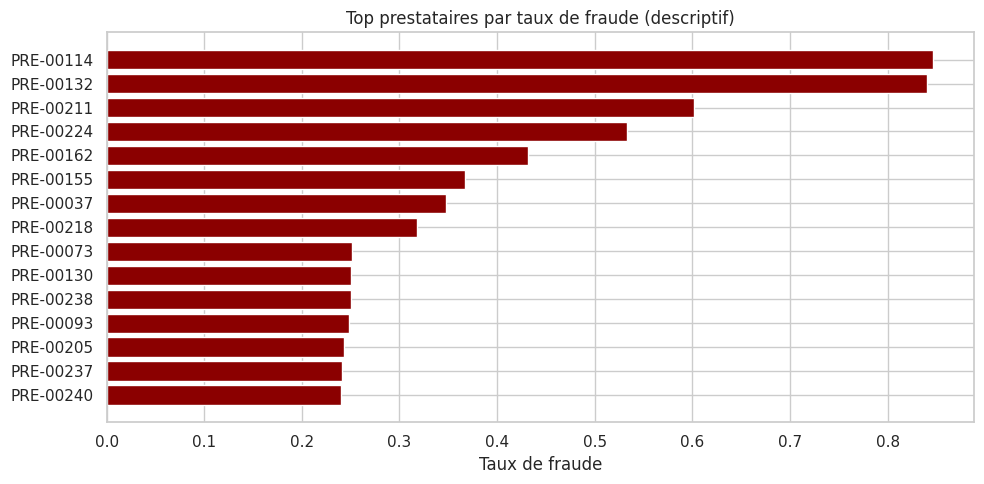

Note : labels_prestataires.est_suspect n'est PAS une feature du modèle.


In [ ]:
# Top prestataires (descriptif uniquement — PAS une feature)
tmp = tables["factures"].merge(labels[["facture_id", "est_fraude"]], on="facture_id")
agg_p = tmp.groupby("prestataire_id").agg(
    n_factures=("facture_id", "count"),
    n_fraudes=("est_fraude", "sum"),
    taux_fraude=("est_fraude", "mean"),
)
agg_p = agg_p[agg_p["n_factures"] >= 20].sort_values("taux_fraude", ascending=False)
print("Top 15 prestataires (volume ≥ 20) — audit uniquement")
display(agg_p.head(15))

fig, ax = plt.subplots(figsize=(10, 5))
top = agg_p.head(15)
ax.barh(top.index.astype(str)[::-1], top["taux_fraude"].values[::-1], color="darkred")
ax.set_title("Top prestataires par taux de fraude (descriptif)")
ax.set_xlabel("Taux de fraude")
plt.tight_layout()
plt.savefig(REPORTS / "01_prestataires_signaux.png", dpi=120)
plt.show()
print("Note : labels_prestataires.est_suspect n'est PAS une feature du modèle.")

## 6. Export

In [ ]:
export.to_csv(OUT / "features_v1.csv", index=False)
print("✓", OUT / "features_v1.csv", export.shape)

schema = {
    "version": "v1",
    "n_variables": len(FEATURES),
    "features": FEATURES,
    "target": "est_fraude",
    "id": "facture_id",
    "note": "Schéma réel : validite_jours, code, tarif_pratique, jours_ouverture. NA métier conservés.",
}
with open(OUT / "schema_v1.json", "w", encoding="utf-8") as fp:
    json.dump(schema, fp, indent=2, ensure_ascii=False)
print("✓", OUT / "schema_v1.json")
print("\nVariables :")
for i, c in enumerate(FEATURES, 1):
    print(f"  {i:2d}. {c}")
print("\n→ Entraîner avec 02_entrainement_predicare.ipynb sur features_v1.csv")

✓ processed/features_v1.csv (84593, 26)
✓ processed/schema_v1.json

Variables :
   1. ord_perimee
   2. nb_lignes_non_prescrites
   3. nb_lignes_qte_excedentaire
   4. presta_apres_fin_convention
   5. ord_apres_soin
   6. ord_autre_assure
   7. soin_avant_adhesion
   8. soin_apres_radiation
   9. ratio_tarif_max
  10. prix_unitaire_max
  11. montant_total
  12. repetition_potentielle
  13. nb_factures_meme_jour_prestataire
  14. type_facture
  15. a_ordonnance
  16. nb_factures_assure_7j
  17. nb_factures_meme_code_7j
  18. delai_heures_facture_precedente
  19. montant_identique_48h
  20. majoration_horaire_incoherente
  21. ratio_tarif_referentiel_max
  22. upcoding_specialite_suspect
  23. soin_jour_ferme

→ Entraîner avec 02_entrainement_predicare.ipynb sur features_v1.csv
